In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
data_path=Path("../data/raw/Monthly-AE-Time-Series-August-2026-YG43sd.xls")
ae=pd.read_excel(
    data_path, sheet_name="Activity", header=13
)

In [4]:
ae=ae.dropna(axis=1, how="all")
ae["Period"]=pd.to_datetime(ae["Period"])


In [5]:
ts=(ae.set_index("Period")["Total Attendances"].asfreq("MS"))

In [6]:
print(len(ts))
print(ts.index.min(), "to", ts.index.max())
print(ts.isna().sum())

193
2010-08-01 00:00:00 to 2026-08-01 00:00:00
0


In [8]:
#test-train splitting yayyy
test_size=24
train=ts.iloc[:-test_size]
test=ts.iloc[-test_size:]
print(train.index.min(), "to", train.index.max())
print(test.index.min(), "to", test.index.max())
print(len(train))
print(len(test))

2010-08-01 00:00:00 to 2024-08-01 00:00:00
2024-09-01 00:00:00 to 2026-08-01 00:00:00
169
24


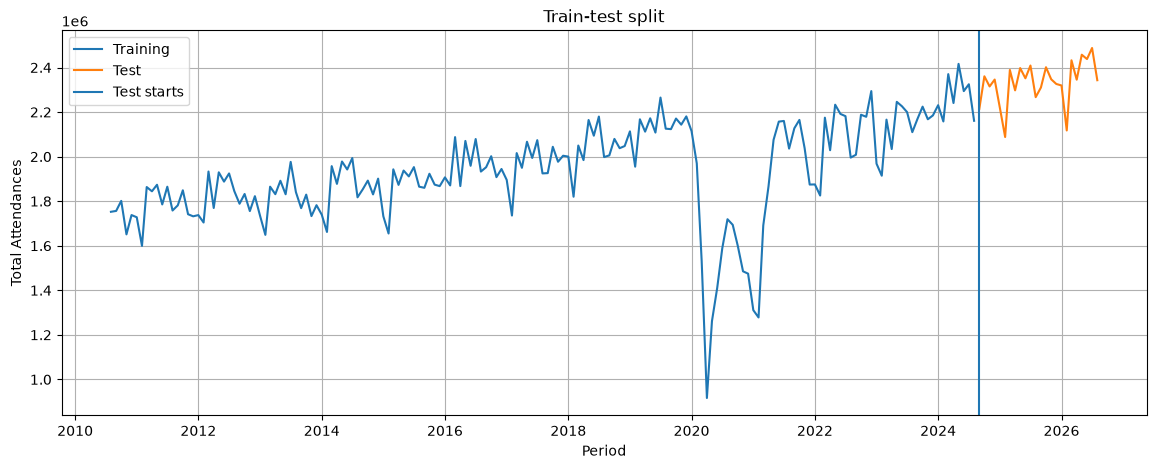

In [10]:
plt.figure(figsize=(14,5))
plt.plot(train.index, train, label="Training")
plt.plot(test.index, test, label="Test")
plt.axvline(test.index[0], label= "Test starts")
plt.title("Train-test split")
plt.xlabel("Period")
plt.ylabel("Total Attendances")
plt.legend()
plt.grid()
plt.show()

In [11]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
can_mod={
    "SARIMA(1,0,0)(1,1,0,12)": ((1,0,0), (1,1,0,12)),
    "SARIMA(1,0,0)(0,1,1,12)": ((1,0,0), (0,1,1,12)),
    "SARIMA(1,0,1)(1,1,0,12)" : ((1,0,1), (1,1,0,12)),
    "SARIMA(1,0,1)(0,1,1,12)": ((1,0,1), (0,1,1,12)),
    "SARIMA(2,0,0)(1,1,0,12)": ((2,0,0), (1,1,0,12)),
    "SARIMA(1,0,0)(1,1,1,12)":((1,0,0), (1,1,1,12))
}
fit_mod={}
for name, (order, seasonal_order) in can_mod.items():
    print(f"Fitting {name}")
    model= SARIMAX(
        train, order=order, seasonal_order=seasonal_order, enforce_stationarity=False, enforce_invertibility=False
    )
    fitted=model.fit(disp=False)
    fit_mod[name]=fitted
    print(f"AIC: {fitted.aic:.2f}")
    print(f"BIC: {fitted.bic:.2f}")
    print()

Fitting SARIMA(1,0,0)(1,1,0,12)
AIC: 3798.44
BIC: 3807.35

Fitting SARIMA(1,0,0)(0,1,1,12)
AIC: 3804.84
BIC: 3813.75

Fitting SARIMA(1,0,1)(1,1,0,12)
AIC: 3784.75
BIC: 3796.63

Fitting SARIMA(1,0,1)(0,1,1,12)
AIC: 3767.70
BIC: 3779.55

Fitting SARIMA(2,0,0)(1,1,0,12)
AIC: 3754.86
BIC: 3766.71

Fitting SARIMA(1,0,0)(1,1,1,12)
AIC: 3795.75
BIC: 3807.63



In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
res=[]
for name, fitted in fit_mod.items():
    forecast=fitted.forecast(steps=len(test))
    mae=mean_absolute_error(test, forecast)
    rmse= np.sqrt(mean_squared_error(test, forecast))
    mape=np.mean(np.abs((test- forecast)/ test))*100
    res.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE in %" : mape
    })
res_df=pd.DataFrame(res)
res_df= res_df.sort_values("MAE").reset_index(drop=True)
res_df

,Model,MAE,RMSE,MAPE in %
0,"SARIMA(1,0,0)(1,1,0,12)",89940.194920,100853.041706,3.818451
1,"SARIMA(1,0,1)(1,1,0,12)",105442.732397,115524.712434,4.479039
2,"SARIMA(1,0,0)(1,1,1,12)",109164.092204,118212.077291,4.645001
3,"SARIMA(2,0,0)(1,1,0,12)",118935.167864,127660.141060,5.063660
4,"SARIMA(1,0,0)(0,1,1,12)",122735.499370,133539.354370,5.213373
5,"SARIMA(1,0,1)(0,1,1,12)",138333.365236,147671.416922,5.885319


In [13]:
best= fit_mod["SARIMA(1,0,0)(1,1,0,12)"]
residual= best.resid
print(residual.describe())

count    1.690000e+02
mean     3.374807e+04
std      2.357846e+05
min     -1.138005e+06
25%     -2.452421e+04
50%      1.629104e+04
75%      7.466737e+04
max      1.752381e+06
dtype: float64


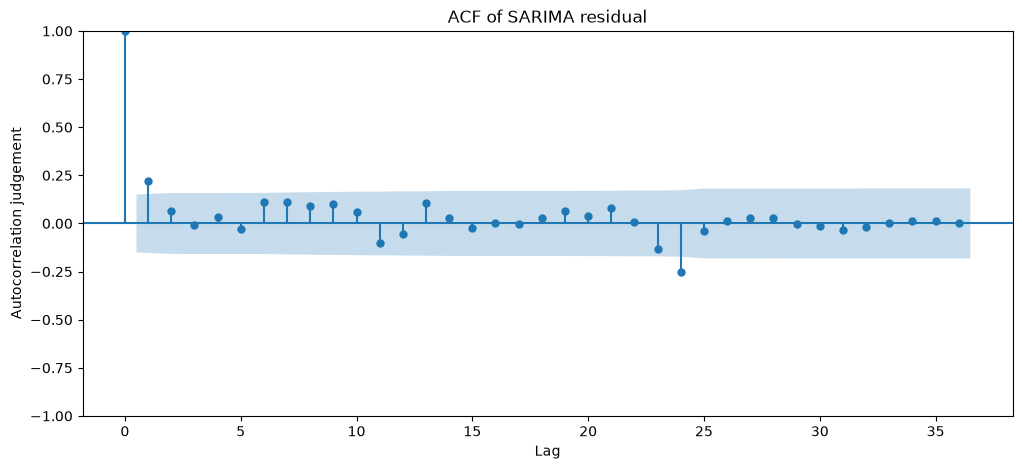

In [14]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
fig, ax=plt.subplots(figsize=(12,5))
plot_acf(residual, lags=36, ax=ax)
ax.set_title("ACF of SARIMA residual")
ax.set_xlabel("Lag")
ax.set_ylabel("Autocorrelation judgement")
plt.show()

In [15]:
ljung=acorr_ljungbox(
    residual, lags=[12,24], return_df=True
)
ljung

,lb_stat,lb_pvalue
12,20.398239,0.059918
24,41.364797,0.015185


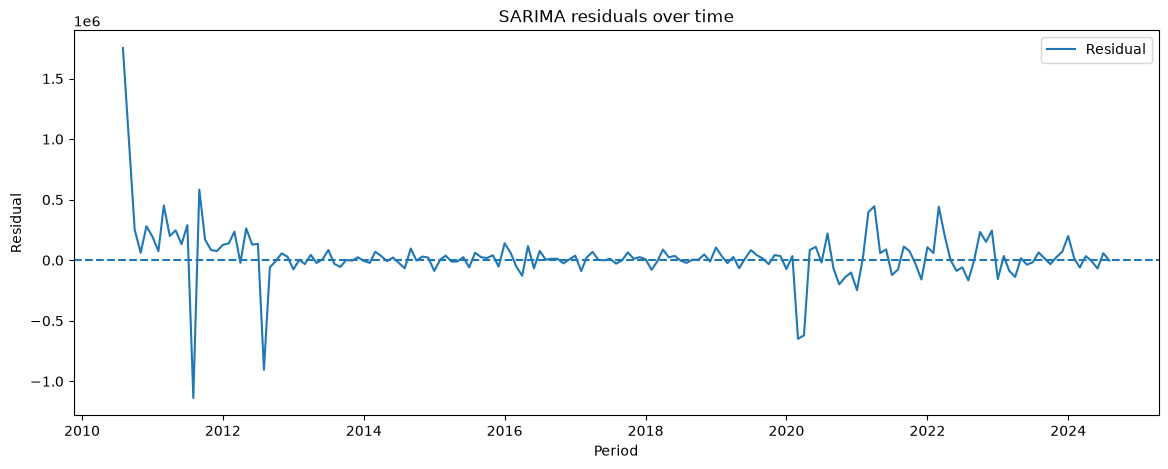

In [16]:
plt.figure(figsize=(14,5))
plt.plot(residual.index, residual, label="Residual")
plt.axhline(0, linestyle="--")
plt.title("SARIMA residuals over time")
plt.xlabel("Period")
plt.ylabel("Residual")

plt.legend()
plt.show()

In [17]:
diag_res= residual.iloc[12:]
print(len(residual))
print(len(diag_res))

169
157


In [18]:
from statsmodels.stats.diagnostic import acorr_ljungbox
ljung_diag=acorr_ljungbox(
    diag_res,
    lags=[12,24],
    return_df=True
)
ljung_diag

,lb_stat,lb_pvalue
12,13.375813,0.342327
24,24.039893,0.459318


In [19]:
#felt an earthquake midway lol
best=fit_mod["SARIMA(1,0,0)(1,1,0,12)"]
forecast=best.forecast(steps=len(test))
fore_df=pd.DataFrame({
    "Actual": test,
    "Forecast": forecast
})
fore_df.head()

,Actual,Forecast
2024-09-01,2214217.0,2.180158e+06
2024-10-01,2360536.0,2.294131e+06
2024-11-01,2314998.0,2.253965e+06
2024-12-01,2345934.0,2.318014e+06
2025-01-01,2218130.0,2.142702e+06


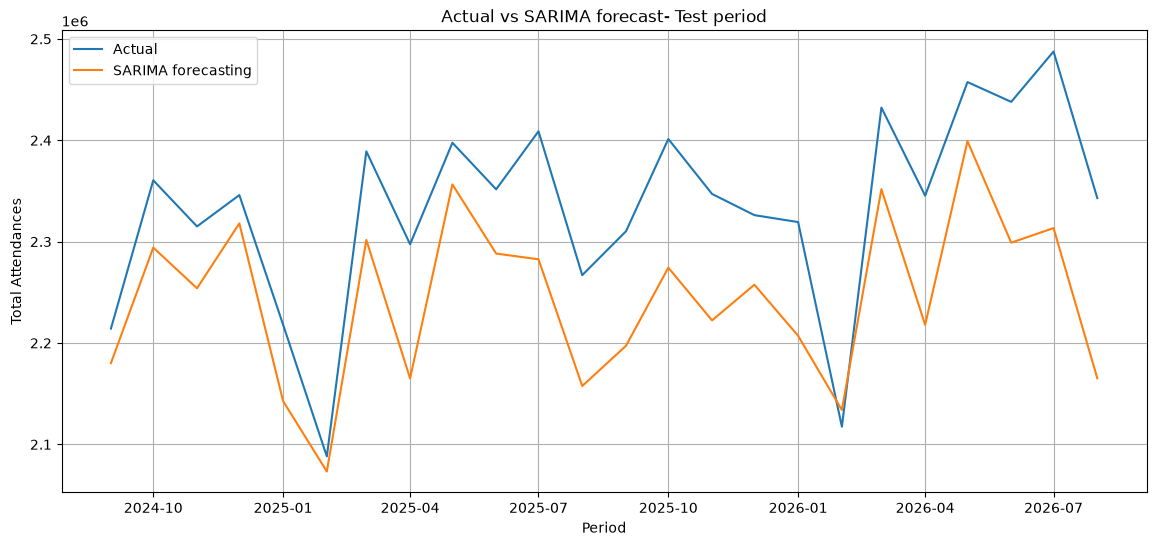

In [20]:
plt.figure(figsize=(14,6))
plt.plot(
    test.index,
    test,
    label="Actual"
)
plt.plot(
    test.index,
    forecast,
    label="SARIMA forecasting"
)
plt.title("Actual vs SARIMA forecast- Test period")
plt.xlabel("Period")
plt.ylabel("Total Attendances")
plt.legend()
plt.grid()
plt.show()


In [21]:
#test-period forecast bias analysis
err= test-forecast
mean_err=err.mean()
bias_per=(mean_err/test.mean())*100
print("Test-period forecast bias")
print("-"* 40 )
print(f"Mean Error: {mean_err:,.2f}")
print(f"MAE: {np.abs(err).mean():,.2f}")
print(f"MAPE: {np.mean(np.abs(err/test))*100:.2f}%")
print(f"Bias: {bias_per:.2f}%")

Test-period forecast bias
----------------------------------------
Mean Error: 88,565.27
MAE: 89,940.19
MAPE: 3.82%
Bias: 3.80%


In [22]:
#model is underforecasting sadly
seasonal_naive_fore= pd.Series(index=test.index, dtype=float)
for i in range(len(test)):
    if i<12:
        seasonal_naive_fore.iloc[i]=train.iloc[-12+i]
    else:
        seasonal_naive_fore.iloc[i]= seasonal_naive_fore.iloc[i-12]
        
naive_mae=mean_absolute_error(test, seasonal_naive_fore)
naive_rmse=np.sqrt(mean_squared_error(test, seasonal_naive_fore))
naive_mape= np.mean(np.abs((test- seasonal_naive_fore)/test))*100
print(f"MAE: {naive_mae:,.2f}")
print(f"RMSE: {naive_rmse:,.2f}")
print(f"MAPE: {naive_mape:.2f}")

MAE: 99,022.54
RMSE: 113,316.77
MAPE: 4.22


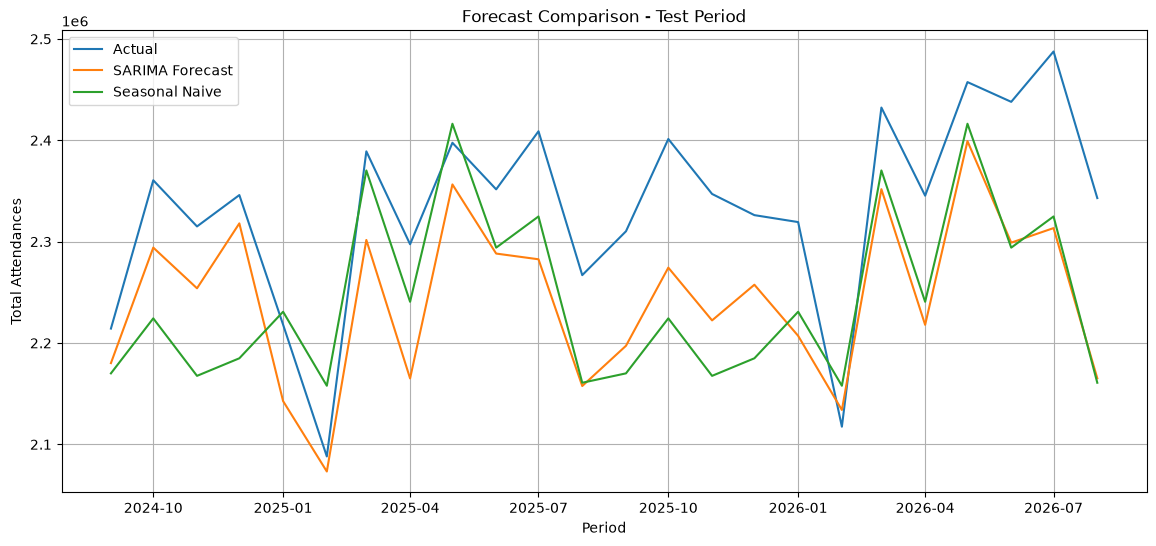

In [23]:
plt.figure(figsize=(14,6))
plt.plot(test.index, test, label="Actual")
plt.plot(test.index, forecast, label="SARIMA Forecast")
plt.plot(test.index, seasonal_naive_fore, label="Seasonal Naive")
plt.title("Forecast Comparison - Test Period")
plt.xlabel("Period")
plt.ylabel("Total Attendances")
plt.legend()
plt.grid()
plt.show()

In [24]:
#trend adjustment
train_yoy=train.pct_change(periods=12)*100
print(train_yoy.describe())

count    157.000000
mean       3.159684
std       16.704838
min      -56.604953
25%       -0.327741
50%        2.490204
75%        5.684414
max      103.609306
Name: Total Attendances, dtype: float64


In [25]:
rec_train=train.iloc[-24:]
rec_yoy=rec_train.pct_change(periods=12).dropna()*100
rec_yoy.describe()
rec_yoy

Period
2023-09-01     8.043708
2023-10-01     1.658663
2023-11-01    -0.514961
2023-12-01    -4.758380
2024-01-01    13.335464
2024-02-01    12.722440
2024-03-01     9.430961
2024-04-01    10.158502
2024-05-01     7.585892
2024-06-01     3.070414
2024-07-01     5.684414
2024-08-01     2.413903
Freq: MS, Name: Total Attendances, dtype: float64

In [26]:
rec_mean=rec_yoy.mean()
rec_median=rec_yoy.median()
print(f"{rec_mean:.2f}%")
print(f"{rec_median:.2f}%")

5.74%
6.64%


In [27]:
#failed benchmark experiment.
trend_growth=rec_median/100
trend_seasonal_naive=(ts.shift(12)*(1+trend_growth)).loc[test.index]
trend_seasonal_naive.head()

Period
2024-09-01    2.314032e+06
2024-10-01    2.371907e+06
2024-11-01    2.311407e+06
2024-12-01    2.329891e+06
2025-01-01    2.378844e+06
Freq: MS, Name: Total Attendances, dtype: float64

In [28]:
trend_naive_mae=mean_absolute_error(test, trend_seasonal_naive)
trend_naive_rmse=np.sqrt(mean_squared_error(test, trend_seasonal_naive))
trend_naive_mape= np.mean(np.abs((test-trend_seasonal_naive)/test))*100

In [29]:
print(f"{trend_naive_mae:,.2f}")
print(f"{trend_naive_rmse:,.2f}")
print(f"{trend_naive_mape:.2f}")

94,970.70
108,618.71
4.11


In [30]:
#trend adjustment failed
#final naive error check
naive_err=test-seasonal_naive_fore
print(naive_err.describe())
print(f"{naive_err.mean():,.2f}")
print(f"{np.abs(naive_err).mean():,.2f}")

count        24.000000
mean      87224.125000
std       73892.810655
min      -69751.000000
25%       43404.750000
50%       96566.000000
75%      144734.250000
max      182168.000000
dtype: float64
87,224.12
99,022.54


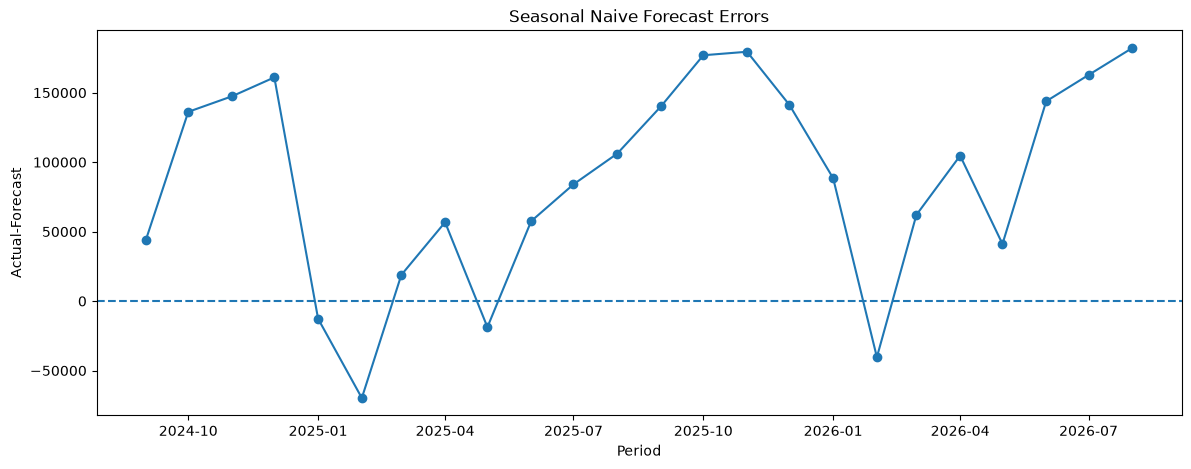

In [31]:
plt.figure(figsize=(14,5))
plt.plot(naive_err.index, naive_err.values, marker="o")
plt.axhline(0, linestyle="--")
plt.title("Seasonal Naive Forecast Errors")
plt.xlabel("Period")
plt.ylabel("Actual-Forecast")
plt.show()

In [32]:
#next station - holt-winters/exponential smoothing
#additional benchmark experiments:

from statsmodels.tsa.holtwinters import ExponentialSmoothing
hw_model=ExponentialSmoothing(
    train, trend="add", seasonal="add", seasonal_periods=12, initialization_method="estimated"
)
hw_fit=hw_model.fit(optimized=True)
hw_fit.params

{'smoothing_level': np.float64(0.9999999850988388),
 'smoothing_trend': np.float64(0.0),
 'smoothing_seasonal': np.float64(1.4901161193847656e-08),
 'damping_trend': nan,
 'initial_level': np.float64(1767603.4003561728),
 'initial_trend': np.float64(-557.6729829579984),
 'initial_seasons': array([ -16100.39647812,  -20894.83199967,   21941.47910065,
         -53397.50362722,  -35264.47692873,  -78654.74106611,
        -157611.06105648,   90556.52245656,  -24240.41899213,
         115282.28898809,   49657.78434213,  109082.47499377]),
 'use_boxcox': False,
 'lamda': None,
 'remove_bias': False}

In [33]:
hw_fore=hw_fit.forecast(steps=len(test))
hw_mae=mean_absolute_error(test, hw_fore)
hw_rmse=np.sqrt(mean_squared_error(test, hw_fore))
hw_mape=np.mean(np.abs((test-hw_fore)/test))*100
print(f"{hw_mae:,.2f}")
print(f"{hw_rmse:,.2f}")
print(f"{hw_mape:.2f}%")

162,472.55
169,685.07
6.92%


In [34]:
#damped trend
hw_dt=ExponentialSmoothing(
    train, trend="add", damped_trend=True, seasonal="add", seasonal_periods=12, initialization_method="estimated"
)
hw_dfit=hw_dt.fit(optimized=True)
hw_dfore=hw_dfit.forecast(steps=len(test))
d_mae=mean_absolute_error(test, hw_dfore)
d_rmse=np.sqrt(mean_squared_error(test, hw_dfore))
d_mape=np.mean(np.abs((test-hw_dfore)/test))*100
print(f"{d_mae:,.2f}")
print(f"{d_rmse:,.2f}")
print(f"{d_mape:.2f}%")


133,415.32
140,081.26
5.69%


In [35]:
#sarima wins
valid_horizon=24
origin=[2019, 2021, 2022]
for year in origin:
 print(f"{year}-08")
 print(f"{year}-09 to {year+2}-08")
 


2019-08
2019-09 to 2021-08
2021-08
2021-09 to 2023-08
2022-08
2022-09 to 2024-08


In [36]:
for year in origin:
    origins=pd.Timestamp(f"{year}-08-01")
    fore_end=pd.Timestamp(f"{year+2}-08-01")
    train_origin=ts.loc[:origins]
    valid=ts.loc[origins+pd.offsets.MonthBegin(1):fore_end]
    print(f"{origins.strftime('%Y-%m')}")
    print(f"{train_origin.index[0].strftime('%Y-%m')}-> {train_origin.index[-1].strftime('%Y-%m')}")
    print(f"{valid.index[0].strftime('%Y-%m')}-> {valid.index[-1].strftime('%Y-%m')}")
    print(f"{len(valid)}")



2019-08
2010-08-> 2019-08
2019-09-> 2021-08
24
2021-08
2010-08-> 2021-08
2021-09-> 2023-08
24
2022-08
2010-08-> 2022-08
2022-09-> 2024-08
24


In [37]:
origins=pd.Timestamp("2019-08-01")
fore_end=pd.Timestamp("2021-08-01")
train_2019=ts.loc[:origins]
val_2019=ts.loc[origins+pd.offsets.MonthBegin(1):fore_end]
model_2019=SARIMAX(train_2019, order=(1,0,0), seasonal_order=(1,1,0,12), enforce_stationarity=False, enforce_invertibility=False)
fit_2019=model_2019.fit(disp=False)
fore_2019=fit_2019.forecast(steps=len(val_2019))
print(len(train_2019))
print(len(val_2019))
print(len(fore_2019))
print(fore_2019.index[0].strftime("%Y-%m"))
print(fore_2019.index[-1].strftime("%Y-%m"))

109
24
24
2019-09
2021-08


In [38]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
mae_2019= mean_absolute_error(val_2019, fore_2019)
rmse_2019=np.sqrt(mean_squared_error(val_2019, fore_2019))
mape_2019=np.mean(np.abs((val_2019-fore_2019)/val_2019)*100)
err_2019=val_2019-fore_2019
bias_2019=err_2019.mean()
bias_pct_2019=(bias_2019/ val_2019.mean()*100)
print(f"{mae_2019:,.2f}")
print(f"{rmse_2019:,.2f}")
print(f"{mape_2019:,.2f}")
print(f"{bias_2019:,.2f}")
print(f"{bias_pct_2019:,.2f}%")

381,342.35
504,345.95
27.61
-359,281.80
-20.55%


In [39]:
origins=pd.Timestamp("2021-08-01")
fore_end=pd.Timestamp("2023-08-01")
train_2021=ts.loc[:origins]
val_2021=ts.loc[origins+pd.offsets.MonthBegin(1):fore_end]
model_2021=SARIMAX(train_2021, order=(1,0,0), seasonal_order=(1,1,0,12), enforce_stationarity=False, enforce_invertibility=False)

In [40]:
fit_2021=model_2021.fit(disp=False)
fore_2021=fit_2021.forecast(steps=len(val_2021))
print(len(train_2021))
print(len(val_2021))
print(len(fore_2021))
print(fore_2021.index[0].strftime("%Y-%m"))
print(fore_2021.index[-1].strftime("%Y-%m"))

133
24
24
2021-09
2023-08


In [41]:
mae_2021=mean_absolute_error(val_2021, fore_2021)
rmse_2021=np.sqrt(mean_squared_error(val_2021, fore_2021))
mape_2021=np.mean(np.abs((val_2021-fore_2021)/val_2021))*100
err_2021=val_2021-fore_2021
bias_2021=err_2021.mean()
bias_pct_2021=(bias_2021/ val_2021.mean())*100
print(f"{mae_2021:,.2f}")
print(f"{rmse_2021:,.2f}")
print(f"{mape_2021:.2f}%")
print(f"{bias_2021:,.2f}")
print(f"{bias_pct_2021:.2f}%")


414,543.95
523,221.70
19.64%
369,413.43
17.65%


In [42]:
origins=pd.Timestamp("2022-08-01")
fore_end=pd.Timestamp("2024-08-01")
train_2022=ts.loc[:origins]
val_2022=ts.loc[origins+pd.offsets.MonthBegin(1):fore_end]
model_2022=SARIMAX(
    train_2022, order=(1,0,0), seasonal_order=(1,1,0,12), enforce_stationarity=False, enforce_invertibility=False
)
fit_2022=model_2022.fit(disp=False)
fore_2022=fit_2022.forecast(steps=len(val_2022))
print(len(train_2022))
print(len(val_2022))
print(len(fore_2022))
print(fore_2022.index[0].strftime("%Y-%m"))
print(fore_2022.index[-1].strftime("%Y-%m"))

145
24
24
2022-09
2024-08


In [43]:
mae_2022=mean_absolute_error(val_2022, fore_2022)
rmse_2022=np.sqrt(mean_squared_error(val_2022, fore_2022))
mape_2022=np.mean(np.abs((val_2022-fore_2022)/val_2022))*100
err_2022=val_2022-fore_2022
bias_2022=err_2022.mean()
bias_pct_2022=(bias_2022/val_2022.mean())*100
print(f"{mae_2022:,.2f}")
print(f"{rmse_2022:,.2f}")
print(f"{mape_2022:.2f}%")
print(f"{bias_2022:,.2f}")
print(f"{bias_pct_2022:.2f}%")


205,607.60
256,082.48
9.42%
205,385.42
9.39%


In [44]:
valid_res=pd.DataFrame([{"Forecast Window":"Sep 2019 - Aug 2021", 
                         "MAE": mae_2019, "RMSE": rmse_2019, "MAPE (%)": mape_2019, "Bias (%)": bias_pct_2019}, {
                             "Forecast Window": "Sep 2021- Aug 2023", "MAE": mae_2021, "RMSE": rmse_2021, "MAPE (%)": mape_2021, "Bias (%)": bias_pct_2021
                         },
                         {
                             "Forecast Window": "Sep 2022- Aug 2024", "MAE": mae_2022, "RMSE": rmse_2022, "MAPE (%)": mape_2022, "Bias (%)": bias_pct_2022
                         }])
print(valid_res.round(2).to_string(index=False))

    Forecast Window       MAE      RMSE  MAPE (%)  Bias (%)
Sep 2019 - Aug 2021 381342.35 504345.95     27.61    -20.55
 Sep 2021- Aug 2023 414543.95 523221.70     19.64     17.65
 Sep 2022- Aug 2024 205607.60 256082.48      9.42      9.39


In [45]:
final_comp=pd.concat([valid_res.assign(Evaluation = "Rolling-origin validation"),
                      pd.DataFrame([{
                          "Forecast Window": "Sep 2024 - Aug 2026",
                          "MAE": 89940.19, "RMSE": 100853.04, "MAPE (%)": 3.82, "Bias (%)": 3.80, "Evaluation": "Final holdout test"
                      }])], ignore_index=True)
print(final_comp.to_string(index=False))

    Forecast Window           MAE          RMSE  MAPE (%)   Bias (%)                Evaluation
Sep 2019 - Aug 2021 381342.351969 504345.951911 27.605129 -20.550433 Rolling-origin validation
 Sep 2021- Aug 2023 414543.951593 523221.699936 19.643065  17.645684 Rolling-origin validation
 Sep 2022- Aug 2024 205607.604168 256082.480841  9.420944   9.393398 Rolling-origin validation
Sep 2024 - Aug 2026  89940.190000 100853.040000  3.820000   3.800000        Final holdout test


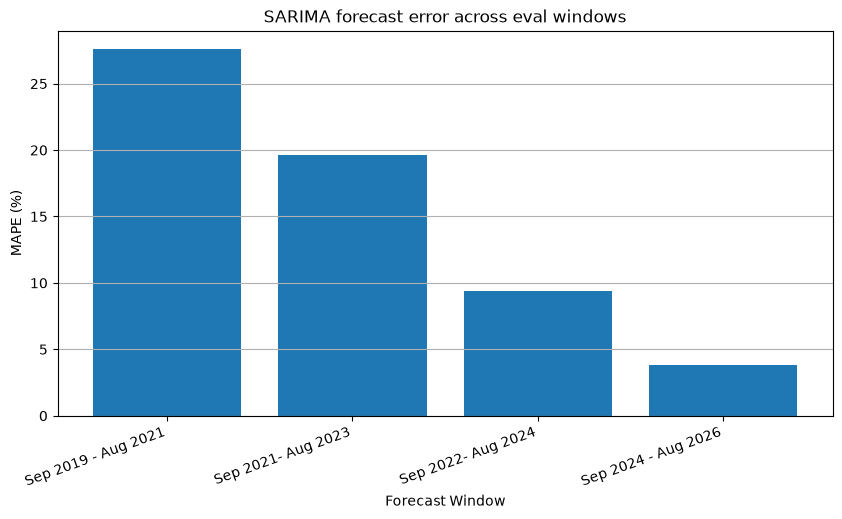

In [46]:
plt.figure(figsize=(10,5))
plt.bar(
    final_comp["Forecast Window"], 
    final_comp["MAPE (%)"]
)
plt.title("SARIMA forecast error across eval windows")
plt.xlabel("Forecast Window")
plt.ylabel("MAPE (%)")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y")
plt.show()

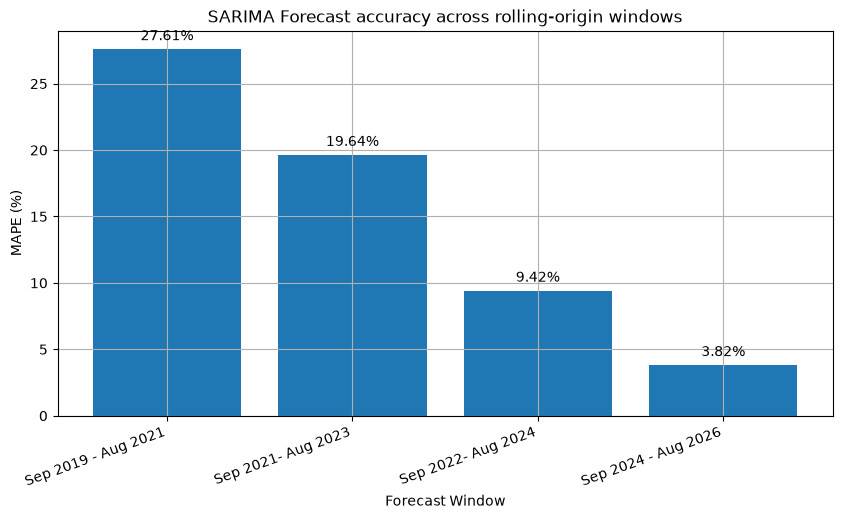

In [47]:
plt.figure(figsize=(10,5))
bars=plt.bar(
    final_comp["Forecast Window"],
    final_comp["MAPE (%)"]
)
plt.bar_label(
    bars, labels=[f"{value:.2f}%"
    for value in final_comp["MAPE (%)"]], 
    padding=4
)
plt.title("SARIMA Forecast accuracy across rolling-origin windows")
plt.xlabel("Forecast Window")
plt.ylabel("MAPE (%)")
plt.xticks(rotation=20, ha="right")
plt.grid()
plt.show()

In [48]:
final_comp.to_csv(
    "../data/processed/sarima_validation_results.csv",
    index=False
)
print("Saved")

Saved


In [49]:
#break day- 12-10-26

In [51]:
out_path=Path("../data/processed/sarima_validation_results.csv")
check=pd.read_csv(out_path)
print(out_path.exists())
print(len(check))
print(check.columns.tolist())
check.round(2)

True
4
['Forecast Window', 'MAE', 'RMSE', 'MAPE (%)', 'Bias (%)', 'Evaluation']


,Forecast Window,MAE,RMSE,MAPE (%),Bias (%),Evaluation
0,Sep 2019 - Aug 2021,381342.35,504345.95,27.61,-20.55,Rolling-origin validation
1,Sep 2021- Aug 2023,414543.95,523221.70,19.64,17.65,Rolling-origin validation
2,Sep 2022- Aug 2024,205607.60,256082.48,9.42,9.39,Rolling-origin validation
3,Sep 2024 - Aug 2026,89940.19,100853.04,3.82,3.80,Final holdout test
